findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: 

N = 10,000,000,  近似標準誤差 ~ 3.16e-04

k     c_1         c_2         c_3         c_4         c_5         c_6      
---------------------------------------------------------------------------
1    +0.79738    +0.00025    -0.32579    -0.00049    +0.21898    +0.00031  
2    +0.00021    +0.68413    -0.00045    -0.39460    +0.00008    +0.21598  
3    -0.44162    -0.00047    +0.61653    -0.00010    -0.41377    +0.00013  

(|c_j| が標準誤差の数倍以下なら実質ゼロとみなす)


findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: 

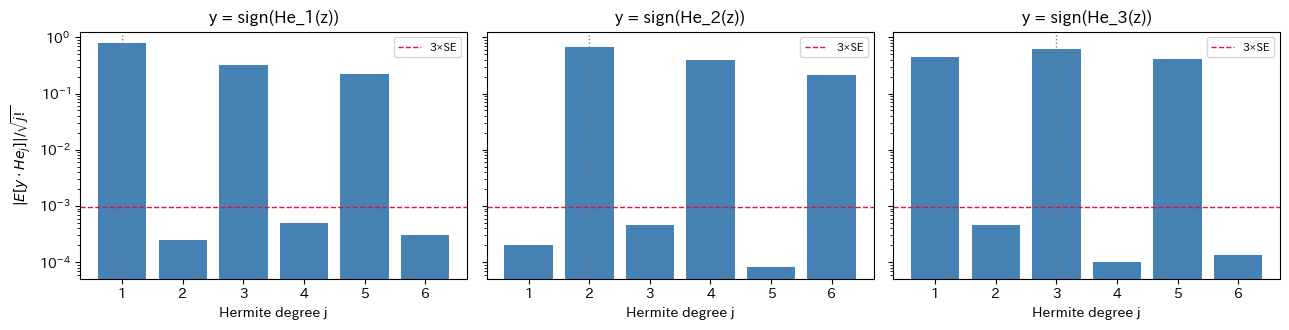

findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: 

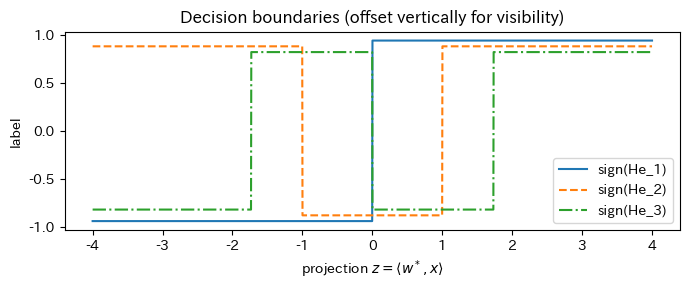

In [3]:
# %% [markdown]
# ## 二値化による information exponent の劣化チェック
#
# y = sign(He_k(z)), z ~ N(0,1) に対して E[y · He_j(z)] を j = 1..6 で推定し、
# j < k の係数が 0 になっているかを確認する。
# sign は奇関数なので、奇数次の He_j との相関が残る可能性が高い。

# %%
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N = 10_000_000   # 係数推定用サンプル数
J_MAX = 6

def hermite_prob(j, z):
    """Hermite 多項式 He_j(z)。
    標準正規分布 N(0,1) に関して直交する系（He_0=1, He_1=z, He_2=z^2-1, ...）で、
    漸化式 He_{n+1}(z) = z·He_n(z) - n·He_{n-1}(z) から計算する。
    """
    if j == 0:
        return np.ones_like(z)
    Hm1, H = np.ones_like(z), z.copy()
    for n in range(1, j):
        Hm1, H = H, z * H - n * Hm1
    return H

def hermite_norm2(j):
    """E[He_j(z)^2] = j!  （正規化に使う）"""
    from math import factorial
    return float(factorial(j))

# %%
z = rng.standard_normal(N)

results = {}
for k in [1, 2, 3]:
    y = np.sign(hermite_prob(k, z))
    coefs = []
    for j in range(1, J_MAX + 1):
        # 正規化 Hermite 基底での係数: E[y·He_j] / sqrt(j!)
        c = np.mean(y * hermite_prob(j, z)) / np.sqrt(hermite_norm2(j))
        coefs.append(c)
    results[k] = np.array(coefs)

# %%
se = 1.0 / np.sqrt(N)   # |y|=1 なので分散は O(1)
print(f"N = {N:,},  近似標準誤差 ~ {se:.2e}\n")

header = "k  " + "".join(f"   c_{j}      " for j in range(1, J_MAX + 1))
print(header)
print("-" * len(header))
for k, c in results.items():
    print(f"{k}  " + "".join(f"{v:+10.5f}  " for v in c))

print("\n(|c_j| が標準誤差の数倍以下なら実質ゼロとみなす)")

# %%
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
js = np.arange(1, J_MAX + 1)
for ax, (k, c) in zip(axes, results.items()):
    ax.bar(js, np.abs(c), color="steelblue")
    ax.axhline(3 * se, color="crimson", ls="--", lw=1, label="3×SE")
    ax.axvline(k, color="gray", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_title(f"y = sign(He_{k}(z))")
    ax.set_xlabel("Hermite degree j")
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$|E[y \cdot He_j]| / \sqrt{j!}$")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 決定境界の確認

# %%
zz = np.linspace(-4, 4, 2000)
fig, ax = plt.subplots(figsize=(7, 3))
for k, style in zip([1, 2, 3], ["-", "--", "-."]):
    ax.plot(zz, np.sign(hermite_prob(k, zz)) * (1 - 0.06 * k),
            style, label=f"sign(He_{k})")
ax.set_xlabel(r"projection $z = \langle w^*, x \rangle$")
ax.set_ylabel("label")
ax.set_title("Decision boundaries (offset vertically for visibility)")
ax.legend()
plt.tight_layout()
plt.show()

findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'TakaoGothic' not found.
findfont: 

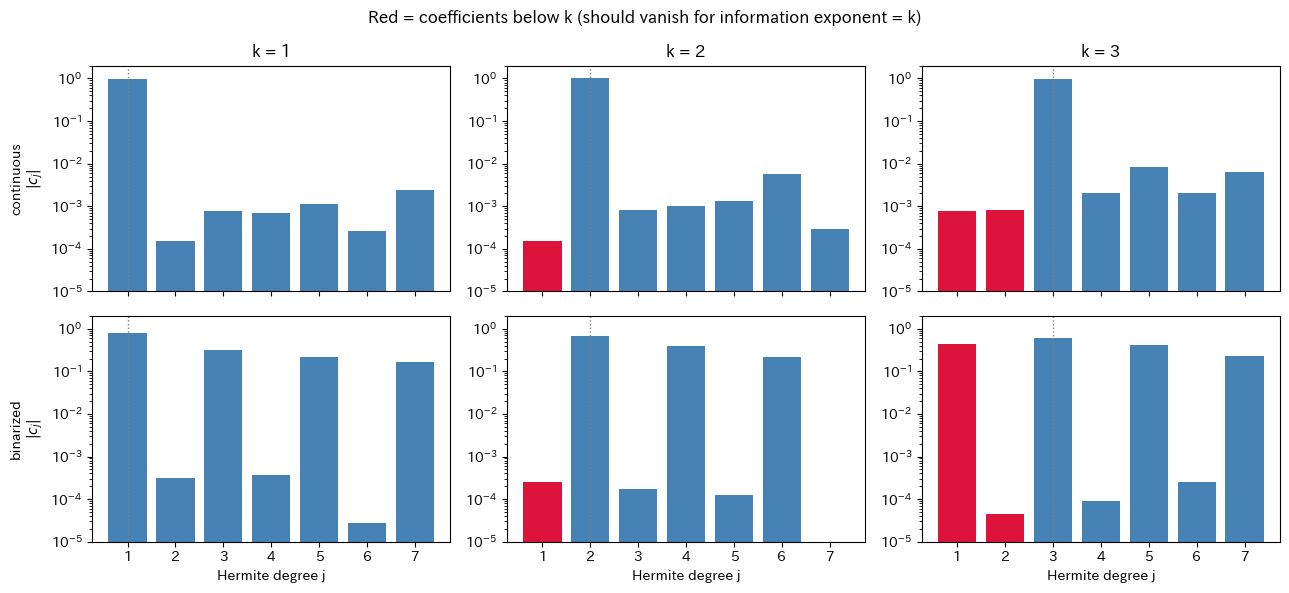

In [4]:
# %% [markdown]
# ## なぜ sign が階層を壊すのか
# 二値化前 He_k(z) と二値化後 sign(He_k(z)) の Hermite 展開を比較する。

# %%
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N = 5_000_000
J_MAX = 7

def hermite_prob(j, z):
    if j == 0:
        return np.ones_like(z)
    Hm1, H = np.ones_like(z), z.copy()
    for n in range(1, j):
        Hm1, H = H, z * H - n * Hm1
    return H

def norm_coefs(y, z, j_max=J_MAX):
    from math import factorial
    return np.array([
        np.mean(y * hermite_prob(j, z)) / np.sqrt(factorial(j))
        for j in range(1, j_max + 1)
    ])

z = rng.standard_normal(N)

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
js = np.arange(1, J_MAX + 1)

for col, k in enumerate([1, 2, 3]):
    raw = hermite_prob(k, z)
    raw = raw / np.std(raw)          # スケールを揃える
    binz = np.sign(hermite_prob(k, z))

    for row, (vals, name) in enumerate([(raw, "continuous"), (binz, "binarized")]):
        c = norm_coefs(vals, z)
        ax = axes[row, col]
        colors = ["crimson" if j < k else "steelblue" for j in js]
        ax.bar(js, np.abs(c), color=colors)
        ax.axvline(k, color="gray", ls=":", lw=1)
        ax.set_yscale("log")
        ax.set_ylim(1e-5, 2)
        if row == 0:
            ax.set_title(f"k = {k}")
        if col == 0:
            ax.set_ylabel(f"{name}\n" + r"$|c_j|$")
        if row == 1:
            ax.set_xlabel("Hermite degree j")

fig.suptitle("Red = coefficients below k (should vanish for information exponent = k)")
plt.tight_layout()
plt.show()